## Student Loan Repayment Strategies
- add in your own salary, loan and investment assumptions to the second cell
- once added then run all cells and the stats panel and plots will be generated

In [9]:
import numpy as np
import pandas as pd

from quant_slc_hedging.data_model import (
    InvestmentModelInputs,
    LoanModelInputs,
    SalaryGrowthType,
    SalaryModelInputs,
)
from quant_slc_hedging.simulation import SimulationHandler
from quant_slc_hedging.strategies.covered_call import CoveredCallStrategy
from quant_slc_hedging.strategies.fixed_pct_repayment import FixedPctRepaymentStrategy
from quant_slc_hedging.strategies.index_fund import IndexFundStrategy
from quant_slc_hedging.strategies.min_repayment import MinRepaymentStrategy
from quant_slc_hedging.stats_plots.stats import calc_stats
from quant_slc_hedging.stats_plots.plots import (
    plot_strategy_comparison,
    plot_writeoff_impact,
)

In [19]:
# Salary assumptions
starting_salary = 50_000
future_mean_salary_growth = 0.05
future_volatility_salary_growth = 0.1
salary_growth_config = SalaryGrowthType(
    growth_type="Custom",
    custom=(future_mean_salary_growth, future_volatility_salary_growth),
)

# Loan assumptions
initial_loan_balance = 30_000
repayment_threshold = 29_385
loan_years_remaining = 20
observations = loan_years_remaining * 12
interest_rate_spread = 0.03  # NOTE: if not a plan 2 loan then set this to 0 to remove the variable interest rate
base_interest_rate = 0.03

# Investment assumptions
initial_investment_balance = 10_000
fixed_excess_of_salary_spare = 0.1  # 10% of salary is invested per month
annual_investment_pct = 0.05
annual_investment_pct_options = 0.07
annual_investment_vol = 0.16
annual_investment_vol_options = 0.20
annual_risk_free_rate = 0.03
covered_call_moneyness = 1.1
payoff_loan_with_investments = True


# Simulation inputs
n_paths = 10_000
seed = 1234

In [20]:
def sim_config() -> Dict:
    salary_rng = np.random.default_rng(seed)
    investment_rng = np.random.default_rng(seed + 1)

    salary_config = SalaryModelInputs(
        starting_salary=starting_salary,
        salary_growth_dist=salary_growth_config,
    )
    loan_config = LoanModelInputs(
        initial_loan_balance=initial_loan_balance,
        remaining_loan_term_months=observations,
        repayment_threshold=repayment_threshold,
        base_interest_rate=base_interest_rate,
        interest_rate_spread=interest_rate_spread,
    )
    investment_config = InvestmentModelInputs(
        initial_investment_balance=initial_investment_balance,
        annual_expected_return=annual_investment_pct,
        annual_vol=annual_investment_vol,
        payoff_loan_with_investments=payoff_loan_with_investments,
    )

    strategies = {
        "Minimum Repayment": MinRepaymentStrategy(investment_config=investment_config),
        f"{int(fixed_excess_of_salary_spare * 100)}% Overpayment": FixedPctRepaymentStrategy(
            fixed_excess_pct=fixed_excess_of_salary_spare,
            repayment_threshold=loan_config.repayment_threshold,
            investment_config=investment_config,
        ),
        f"{int(fixed_excess_of_salary_spare * 100)}% Invested Index Fund": IndexFundStrategy(
            investment_config=investment_config,
            investment_pct=fixed_excess_of_salary_spare,
            repayment_pct=0.0,
            repayment_threshold=loan_config.repayment_threshold,
            rng_gen=investment_rng,
            n_paths=n_paths,
            n_obs=observations,
        ),
        f"{int(fixed_excess_of_salary_spare * 100 / 2)}% Invested Index Fund {int(fixed_excess_of_salary_spare * 100 / 2)}% Overpayment": IndexFundStrategy(
            investment_config=investment_config,
            investment_pct=fixed_excess_of_salary_spare / 2,
            repayment_pct=fixed_excess_of_salary_spare / 2,
            repayment_threshold=loan_config.repayment_threshold,
            rng_gen=investment_rng,
            n_paths=n_paths,
            n_obs=observations,
        ),
        f"{int(fixed_excess_of_salary_spare * 100)}% Invested Covered Call": CoveredCallStrategy(
            investment_config=investment_config,
            investment_pct=fixed_excess_of_salary_spare / 2,
            repayment_pct=0,
            target_moneyness=covered_call_moneyness,
            repayment_threshold=loan_config.repayment_threshold,
            rng_gen=investment_rng,
            n_paths=n_paths,
            n_obs=observations,
        ),
        f"{int(fixed_excess_of_salary_spare * 100)}% Invested Covered Call {int(fixed_excess_of_salary_spare * 100)}% Overpayment": CoveredCallStrategy(
            investment_config=investment_config,
            investment_pct=fixed_excess_of_salary_spare / 2,
            repayment_pct=fixed_excess_of_salary_spare / 2,
            target_moneyness=covered_call_moneyness,
            repayment_threshold=loan_config.repayment_threshold,
            rng_gen=investment_rng,
            n_paths=n_paths,
            n_obs=observations,
        ),
    }

    return {
        "salary_rng": salary_rng,
        "investment_rng": investment_rng,
        "salary_config": salary_config,
        "loan_config": loan_config,
        "investment_config": investment_config,
        "observations": observations,
        "n_paths": n_paths,
        "strategies": strategies,
    }


results = {}
config_dict = sim_config()
strategies = config_dict["strategies"]
for name, strategy in strategies.items():
    sim = SimulationHandler(
        salary_config=config_dict["salary_config"],
        loan_config=config_dict["loan_config"],
        investment_config=config_dict["investment_config"],
        strategy=strategy,
        n_paths=config_dict["n_paths"],
        observations=config_dict["observations"],
        salary_rng=config_dict["salary_rng"],
    )
    results[name] = sim.run_simulation()

Simulation finished
Simulation finished
Simulation finished
Simulation finished
Simulation finished
Simulation finished


## Generate Stats Panel
- contains median terminal wealth pre and post write off
- includes probability of repayment
- set summary_only to False for more further stats

In [21]:
metrics_df = pd.concat(
    [
        calc_stats(results[strategy_name], strategy_name, "Custom", summary_only=True)
        for strategy_name in config_dict["strategies"].keys()
    ]
)
metrics_df

,Growth Regime,Strategy,Median Wealth After Write-Off,10th Percentile Wealth After Write-Off,Probability of Repayment Before Write-Off,Median Wealth Before Write-Off
0,Custom,Minimum Repayment,18162.144592,18162.144592,0.8788,18162.144592
0,Custom,10% Overpayment,18162.144592,18162.144592,0.9935,18162.144592
0,Custom,10% Invested Index Fund,122116.527625,49503.824510,0.9978,122116.527625
0,Custom,5% Invested Index Fund 5% Overpayment,61585.297806,24872.221718,0.9984,61585.297806
0,Custom,10% Invested Covered Call,56470.688697,21374.138265,0.9921,56470.688697
0,Custom,10% Invested Covered Call 10% Overpayment,61510.949082,24888.464993,0.9987,61510.949082


## Generate Plots
- shows terminal wealth after write off for all strategies using the custom salary inputs, error bars represent 10, 90 percentiles
- also shows difference between terminal wealth for a given strategy

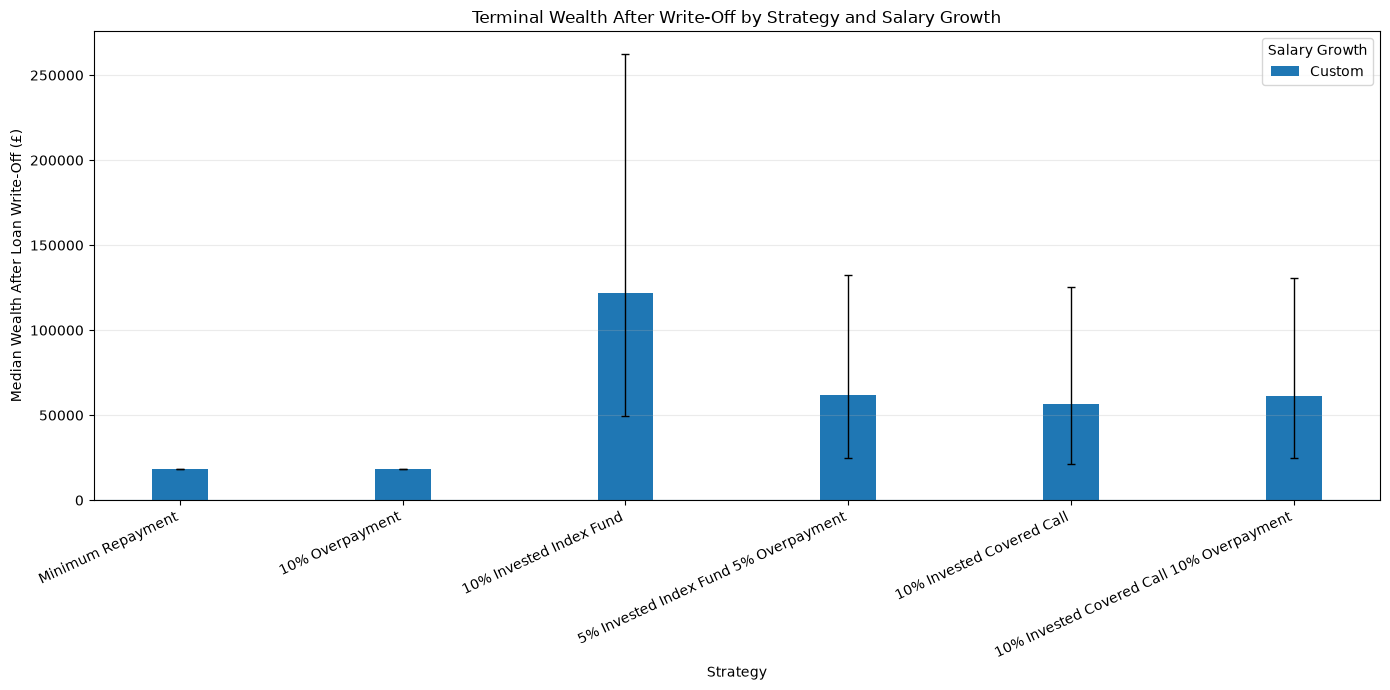

,Growth Regime,Strategy,Median Wealth,P10,P90
0,Custom,Minimum Repayment,18162.144592,18162.144592,18162.144592
1,Custom,10% Overpayment,18162.144592,18162.144592,18162.144592
2,Custom,10% Invested Index Fund,122116.527625,49503.824510,262655.406925
3,Custom,5% Invested Index Fund 5% Overpayment,61585.297806,24872.221718,132526.705850
4,Custom,10% Invested Covered Call,56470.688697,21374.138265,125291.854880
5,Custom,10% Invested Covered Call 10% Overpayment,61510.949082,24888.464993,130533.578975


In [22]:
plot_strategy_comparison({"Custom": results}, regimes=["Custom"])

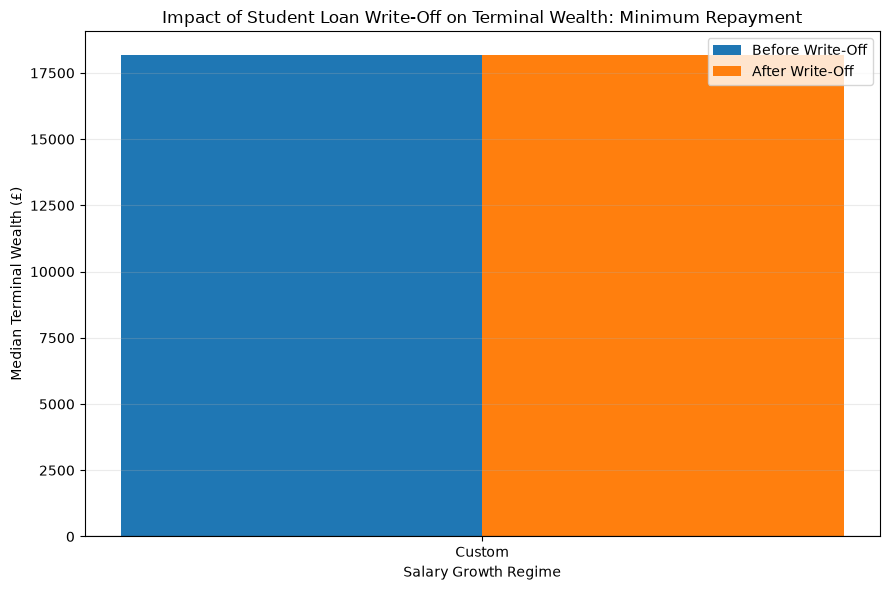

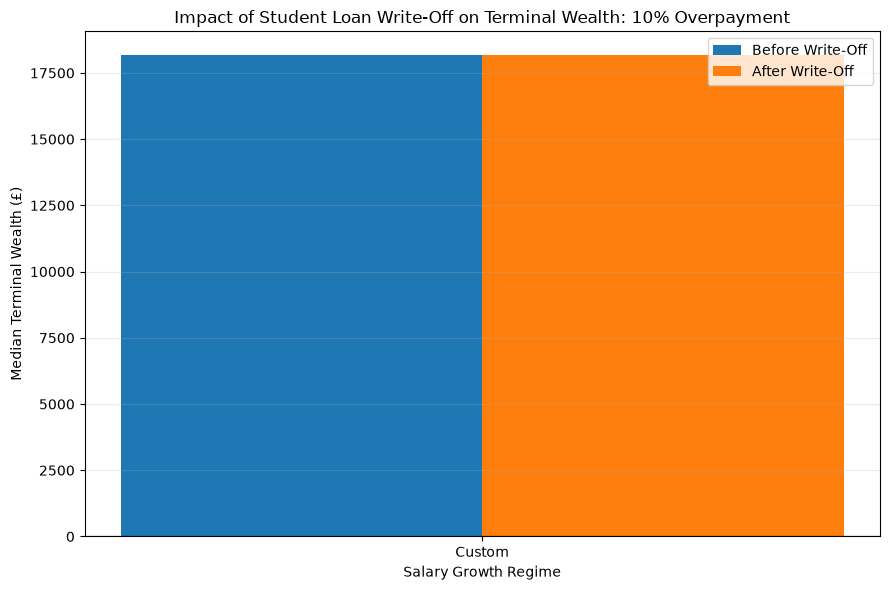

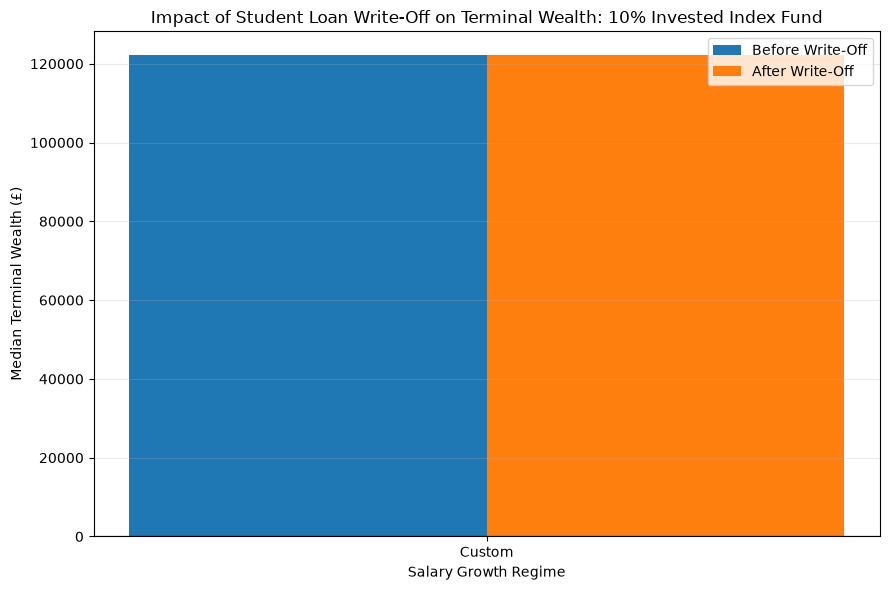

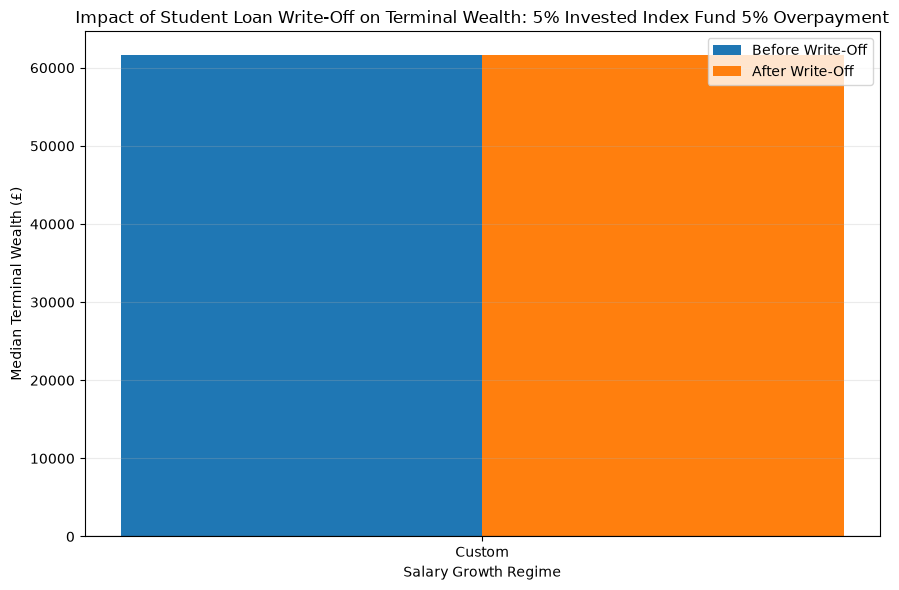

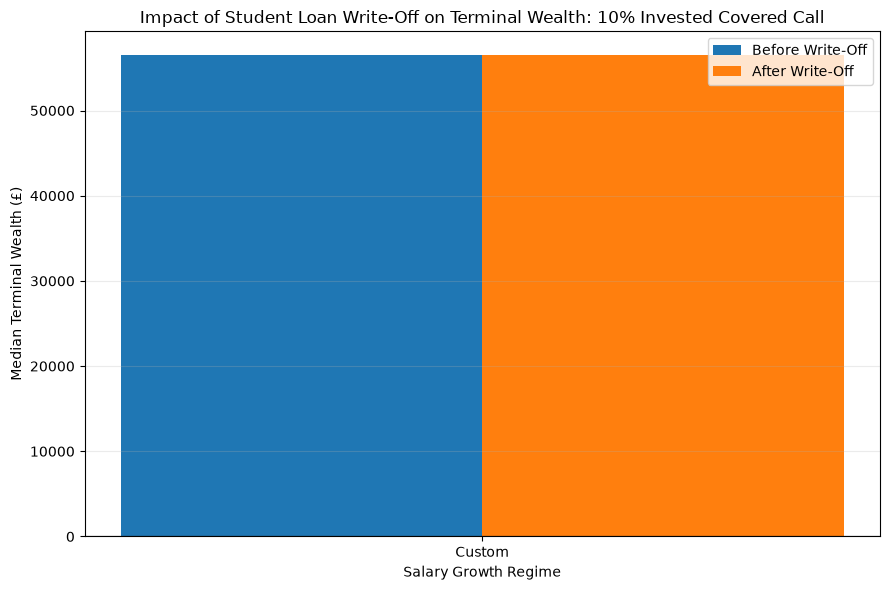

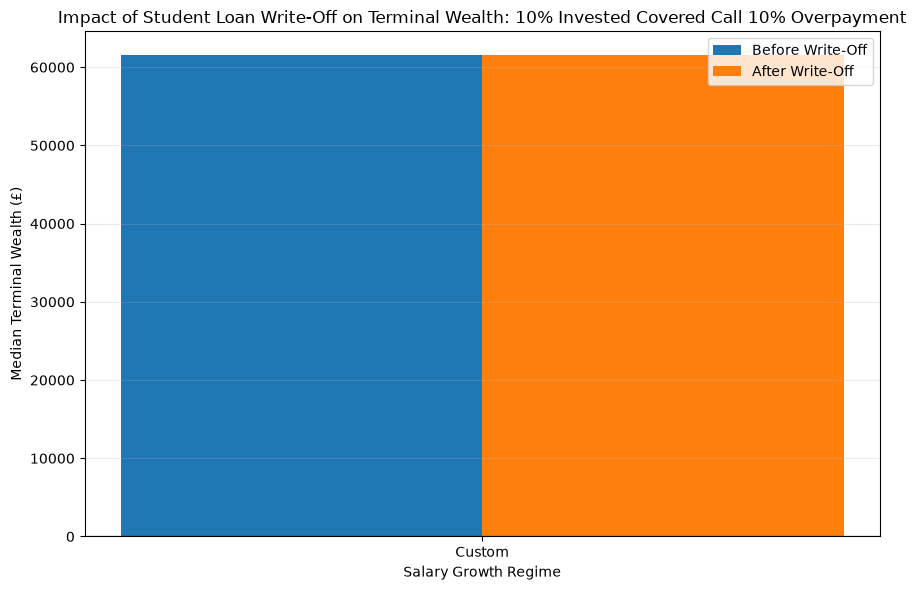

In [23]:
for strategy in results.keys():
    plot_writeoff_impact({"Custom": results}, regimes=["Custom"], strategy=strategy)